In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../utils"))  # repo utils/ (vendored sweep + shared helpers)
import sys; sys.path.append("../utils")
from fft_sup_imports import * 
%matplotlib inline
update_rc_params('paper')
import copy

In [2]:
def detrend_derivative(x, y):
    """Detrend by differentiation. Removes any smooth background by construction.
    Returns (detrended, background) to match the other detrend_* signatures."""
    return np.gradient(np.asarray(y, float), np.asarray(x, float)), np.zeros_like(y)

def plot_fft_linecut(fig, ax, target_density, filter_method="poly", analyzer=None,
                     norm_band=(0.5, 3.0), padding=8, filter_lims=(1, 4),
                     linecut_color="b", xlim=None, ylim=(0, 1.2),
                     butter_cutoff=None, normalized_freq=False, verbose=False):
    """Plot the normalised SdH power spectrum at one density.

    norm_band : (lo, hi), always in units of n_SdH/n. The tallest peak inside
        this band is set to 1. Chosen in frequency units, not array index, so
        it does not depend on padding or on how far the frequency axis runs.
    normalized_freq : if True the x axis is n_SdH/n, otherwise n_SdH in
        units of 1e12 cm^-2.
    """
    if filter_method == "poly":
        fft, freq = analyzer.get_fft(detrend_poly, {'degree': 1}, padding, filter_lims)
    elif filter_method == "spline":
        fft, freq = analyzer.get_fft(detrend_spline, {'n_knots': 6}, padding, filter_lims)
    elif filter_method == "butter":
        fft, freq = analyzer.get_fft(detrend_butterworth,
                                     {'cutoff': butter_cutoff, 'order': 4},
                                     padding, filter_lims)
    elif filter_method == "derivative":
        fft, freq = analyzer.get_fft(detrend_derivative, {}, padding, filter_lims)
    else:
        raise ValueError(f"Unknown filter_method: {filter_method!r}")

    density_idx = np.argmin(np.abs(analyzer.density - target_density))
    density_res = analyzer.density[density_idx]

    freq_col = freq[:, density_idx]          # n_SdH / n
    fft_col = np.abs(fft[:, density_idx])

    mask = (freq_col > norm_band[0]) & (freq_col < norm_band[1])
    if not mask.any():
        raise ValueError(f"norm_band {norm_band} contains no frequency points; "
                         f"axis spans {freq_col.min():.2f} to {freq_col.max():.2f}")
    psd = (fft_col/np.max(fft_col[mask]))**2

    x = freq_col if normalized_freq else freq_col*density_res
    if xlim is None:
        xlim = (0, 5) if normalized_freq else (0, 2.0)

    if verbose:
        peak = freq_col[mask][np.argmax(fft_col[mask])]
        print(f"requested n = {target_density:.3f}, using n = {density_res:.3f}")
        print(f"freq axis spans {freq_col.min():.2f} to {freq_col.max():.2f} in n_SdH/n "
              f"({freq_col.min()*density_res:.2f} to {freq_col.max()*density_res:.2f} "
              f"in 1e12 cm^-2)")
        print(f"peak in norm band at n_SdH/n = {peak:.3f} "
              f"(n_SdH = {peak*density_res:.3f})")

    ax.plot(x, psd, color=linecut_color)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_xlabel(r'$n_{\mathrm{SdH}}/n$' if normalized_freq
                  else r'$n_{\mathrm{SdH}}$ $(10^{12}\,\mathrm{cm}^{-2})$')
    ax.set_ylabel('|FFT|$^2$ (a.u.)')
    ax.xaxis.set_major_locator(plt.MaxNLocator(8))
    ax.yaxis.set_major_locator(plt.MaxNLocator(5))

    return x, psd, density_res

# Large fan for reference

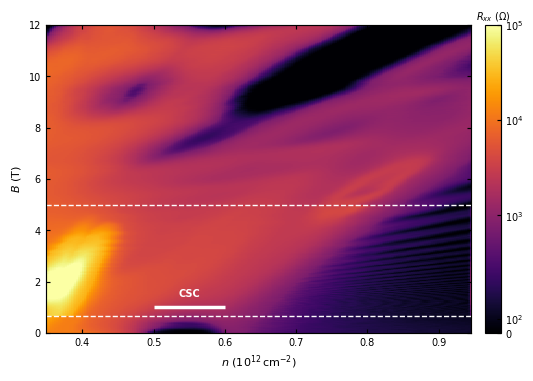

In [4]:
# ---------------------------------------------------------------------------
# Standalone: stitched raw Landau fan, Rxx(n, B) from 0.02 to 12 T
# Files 1637 (low B) | 1840 (mid) | 1959 (high), joined at zf_seams.
# ---------------------------------------------------------------------------
ZF_DN      = 0.012                     # density offset applied to 1637 to match 1840
ZF_BMIN    = 0.02                      # drop 1637's glitched first two points
zf_seams   = (0.65, 5.0)               # 1637 | 1840 | 1959

analyzer_zeroB = Lf_analysis(1637, contact=2)
analyzer_lowB  = Lf_analysis(1840, contact=2)
analyzer_highB = Lf_analysis(1959, contact=2)


def zf_sorted(analyzer):
    """Raw Rxx with B ascending and de-duplicated, columns in ascending density."""
    B = np.asarray(analyzer.B_raw, float)
    Rxx = np.asarray(analyzer.Rxx_raw, float)
    order = np.argsort(B)
    B, Rxx = B[order], Rxx[order]
    keep = np.append(np.diff(B) > 0, True)     # drop repeated / flat-B points
    B, Rxx = B[keep], Rxx[keep]
    dens_order = np.argsort(np.asarray(analyzer.density, float))
    return B, Rxx[:, dens_order], np.asarray(analyzer.density, float)[dens_order]


zf_dens = zf_sorted(analyzer_lowB)[2]      # common density axis for the fan


def zf_block(analyzer, blims, dn=0.0):
    """One file's rows over [blims[0], blims[1]), resampled onto zf_dens + dn."""
    B, Rxx, dens = zf_sorted(analyzer)
    m = (blims[0] <= B) & (B < blims[1])
    return B[m], np.array([np.interp(zf_dens + dn, dens, row) for row in Rxx[m]])


def zf_map():
    """Stitched raw Rxx(n, B) over 0.02-12 T. Returns (density, B, Rxx)."""
    blocks = [
        zf_block(analyzer_zeroB, (ZF_BMIN, zf_seams[0]), dn=ZF_DN),
        zf_block(analyzer_lowB, zf_seams),
        zf_block(analyzer_highB, (zf_seams[1], np.inf)),
    ]
    return (zf_dens,
            np.concatenate([b[0] for b in blocks]),
            np.concatenate([b[1] for b in blocks], axis=0))

def zf_cut(n_target):
    """Continuous raw linecut, 0.02-12 T, stitched at zf_seams."""
    segs = [
        zf_segment(analyzer_zeroB, n_target, (ZF_BMIN, zf_seams[0]), dn=ZF_DN),
        zf_segment(analyzer_lowB, n_target, (zf_seams[0], zf_seams[1])),
        zf_segment(analyzer_highB, n_target, (zf_seams[1] + 1e-9, np.inf)),
    ]
    return (np.concatenate([s[0] for s in segs]),
            np.concatenate([s[1] for s in segs]))

def zf_segment(analyzer, n_target, blims, dn=0.0):
    """Raw Rxx(B) at exactly n_target + dn over blims. No background subtraction."""
    B = np.asarray(analyzer.B_raw, float)
    Rxx = np.asarray(analyzer.Rxx_raw, float)
    order = np.argsort(B)
    B, Rxx = B[order], Rxx[order]
    keep = np.append(np.diff(B) > 0, True)     # drop repeated / flat-B points
    B, Rxx = B[keep], Rxx[keep]
    dens_order = np.argsort(analyzer.density)
    dens = np.asarray(analyzer.density, float)[dens_order]
    cut = np.array([np.interp(n_target + dn, dens, row[dens_order]) for row in Rxx])
    m = (blims[0] <= B) & (B <= blims[1]) & np.isfinite(cut)
    return B[m], cut[m]



fig, ax = plt.subplots(figsize=(6.0, 4))
dens, B, Rxx_map = zf_map()

norm = colors.SymLogNorm(linthresh=750, vmin=0, vmax=1e5)
plot = ax.pcolormesh(dens, B, Rxx_map, norm=norm, cmap='inferno',
                     rasterized=True, lw=0)
ax.set_xlabel(r'$n$ $\left(10^{12}\,\mathrm{cm}^{-2}\right)$')
ax.set_ylabel(r'$B$ (T)')
ax.set_xlim(dens.min(), dens.max())
ax.set_ylim(0, B.max())
ax.axhline(0.65, color="white", ls="--", lw=1)
ax.axhline(5, color="white", ls="--", lw=1)


# White segment marking the zero-field density extent of the CSC
CSC_EXTENT = (0.50, 0.60)
csc_B = 1                                   # height at which to draw it
ax.plot(CSC_EXTENT, [csc_B, csc_B], color='w', lw=2.5, solid_capstyle='butt',
        zorder=3)
ax.annotate('CSC', (np.mean(CSC_EXTENT), csc_B), xytext=(0, 6),
            textcoords='offset points', color='w', fontweight='bold',
            ha='center', va='bottom', fontsize=7, zorder=3)


cb = fig.colorbar(plot, ax=ax, ticks=[0, 1e2, 1e3, 1e4, 1e5], pad=0.03,
                  fraction=0.055)
cb.ax.set_title(r'$R_{xx}$ ($\Omega$)', pad=4, fontsize=7)

plt.savefig('figS_highfield_fan.pdf', dpi=600, bbox_inches='tight',
            pad_inches=0.02, transparent=False)

# Derivative detrending

In [38]:
from matplotlib.patches import Rectangle

dv_box_kw = dict(fill=True,                         # shade the inside of the box
                 facecolor=(0.5, 0.5, 0.5, 0.2),    # gray fill as (R, G, B, opacity); 0.2 is the fill alpha
                 edgecolor='k',                     # black outline, fully opaque
                 lw=0.5,                              # outline width in points
                 zorder=3)                          # drawn on top of the trace


def add_zoom_box(ax, xlim, ylim):
    """Outline the region (xlim, ylim) on `ax`, in data coordinates."""
    x0, x1 = xlim    # left and right edges of the zoomed view
    y0, y1 = ylim    # bottom and top edges of the zoomed view
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, **dv_box_kw))
    ax.autoscale_view()    # axes still on automatic limits grow to keep the whole box in view

requested n = 0.552, using n = 0.551
freq axis spans 0.00 to 34.77 in n_SdH/n (0.00 to 19.17 in 1e12 cm^-2)
peak in norm band at n_SdH/n = 1.682 (n_SdH = 0.927)
requested n = 0.800, using n = 0.801
freq axis spans 0.00 to 23.94 in n_SdH/n (0.00 to 19.17 in 1e12 cm^-2)
peak in norm band at n_SdH/n = 1.007 (n_SdH = 0.806)


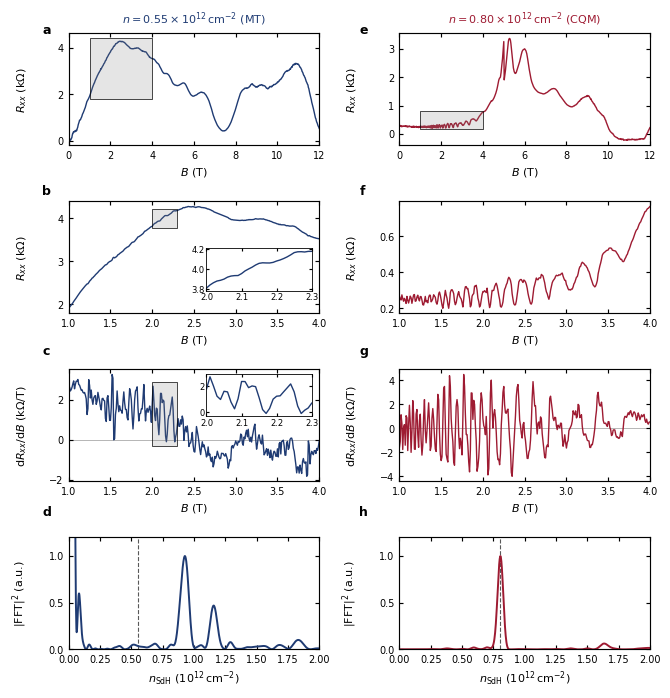

In [41]:
dv_targets = [0.552, 0.80]
dv_colors  = ['#1F3B73', '#9E1B32']   # navy / crimson
labels = ["MT", "CQM"]
dv_zoom    = (1, 4)
dv_zoom_ypad = 0.05

dv_inset        = (2, 2.3)
dv_inset_pos    = [[0.55, 0.20, 0.42, 0.38],    # panel b, left column: lower right
                   [0.06, 0.56, 0.42, 0.38]]    # panel b, right column: upper left
dv_inset_pos_c  = [[0.55, 0.58, 0.42, 0.38],    # panel c, left column: upper right
                   [0.06, 0.56, 0.42, 0.38]]    # panel c, right column: upper left


def add_inset(ax, x, y, window, pos, color):
    """Inset showing x, y over `window`, with the region shaded on the parent."""
    mi = (window[0] <= x) & (x <= window[1])
    axi = ax.inset_axes(pos)
    axi.plot(x[mi], y[mi], lw=1, color=color)
    axi.set_xlim(*window)
    pad = 0.08*np.ptp(y[mi])
    axi.set_ylim(y[mi].min() - pad, y[mi].max() + pad)
    axi.tick_params(labelsize=6, length=2, pad=1.5)
    axi.locator_params(axis='x', nbins=3)
    axi.locator_params(axis='y', nbins=3)
    add_zoom_box(ax, axi.get_xlim(), axi.get_ylim())   # box on the parent = what the inset shows
    for spine in axi.spines.values():
        spine.set_linewidth(0.6)
    return axi


ncols = len(dv_targets)
fig, axes = plt.subplots(4, ncols, figsize=(7.5, 8.0))

for col, (n, color) in enumerate(zip(dv_targets, dv_colors)):
    ax_raw, ax_zoom, ax_der, ax_fft = axes[:, col]
    B_cut, Rxx = zf_cut(n)

    ax_raw.set_title(rf'$n = {n:.2f} \times 10^{{12}}\,\mathrm{{cm}}^{{-2}}$' \
                     + " ({:s})".format(labels[col]),
                     color=color, pad=8)

    # (a) raw trace, full field range, no processing of any kind
    ax_raw.plot(B_cut, Rxx*1e-3, lw=1, color=color)
    ax_raw.set_xlim(0, B_cut.max())
    ax_raw.set_ylabel(r'$R_{xx}$ (k$\Omega$)')
    ax_raw.set_xlabel(r'$B$ (T)')

    # (b) same raw data, zoomed on the SdH window
    m = (dv_zoom[0] <= B_cut) & (B_cut <= dv_zoom[1])
    ax_zoom.plot(B_cut[m], Rxx[m]*1e-3, lw=1, color=color)
    ax_zoom.set_xlim(*dv_zoom)
    y = Rxx[m]*1e-3
    pad = dv_zoom_ypad*np.ptp(y)
    ax_zoom.set_ylim(y.min() - pad, y.max() + pad)
    add_zoom_box(ax_raw, ax_zoom.get_xlim(), ax_zoom.get_ylim())   # box on the raw panel = what the zoom panel shows
    ax_zoom.set_ylabel(r'$R_{xx}$ (k$\Omega$)')
    ax_zoom.set_xlabel(r'$B$ (T)')

    if col == 0:
        add_inset(ax_zoom, B_cut[m], Rxx[m]*1e-3, dv_inset,
                  dv_inset_pos[col], color)

    # (c) numerical derivative. No filter, no detrending kernel.
    dRdB = np.gradient(Rxx[m], B_cut[m])
    ax_der.plot(B_cut[m], dRdB*1e-3, lw=1, color=color)
    ax_der.axhline(0, color='0.6', lw=0.5, zorder=0)
    ax_der.set_xlim(*dv_zoom)
    ax_der.set_ylabel(r'$\mathrm{d}R_{xx}/\mathrm{d}B$ (k$\Omega$/T)')
    ax_der.set_xlabel(r'$B$ (T)')

    if col == 0:
        add_inset(ax_der, B_cut[m], dRdB*1e-3, dv_inset,
                  dv_inset_pos_c[col], color)

    # (d) FFT of the derivative, same pipeline and normalisation as the filtered case
    _, _, density_res = plot_fft_linecut(fig, ax_fft, n, filter_method="derivative",
                                         analyzer=analyzer_lowB, filter_lims=dv_zoom,
                                         linecut_color=color, verbose=True)
    ax_fft.axvline(density_res, color='0.35', ls='--', lw=0.8, zorder=0)  # n_SdH = n

letters = list(map(chr, range(97, 97 + 26)))
label_spacer = 0.035
for col in range(ncols):
    for row in range(4):
        ax = axes[row, col]
        ax.locator_params(axis='y', nbins=4, steps=[1, 2, 5, 10])
        ax.yaxis.set_label_coords(-0.16, 0.5)
        p = ax.get_position()
        fig.text(p.x0 - label_spacer, p.y1, letters[4*col + row], fontweight='bold')

fig.subplots_adjust(hspace=0.5, wspace=0.32)
plt.savefig('figS_derivative_detrend.pdf', dpi=600, bbox_inches='tight',
            pad_inches=0.02, transparent=False)

# Side by side comparison between derivative detrending and butterworth detrending at same density

derivative
requested n = 0.550, using n = 0.551
freq axis spans 0.00 to 34.77 in n_SdH/n (0.00 to 19.17 in 1e12 cm^-2)
peak in norm band at n_SdH/n = 1.682 (n_SdH = 0.927)
butter
requested n = 0.550, using n = 0.551
freq axis spans 0.00 to 34.77 in n_SdH/n (0.00 to 19.17 in 1e12 cm^-2)
peak in norm band at n_SdH/n = 1.678 (n_SdH = 0.925)


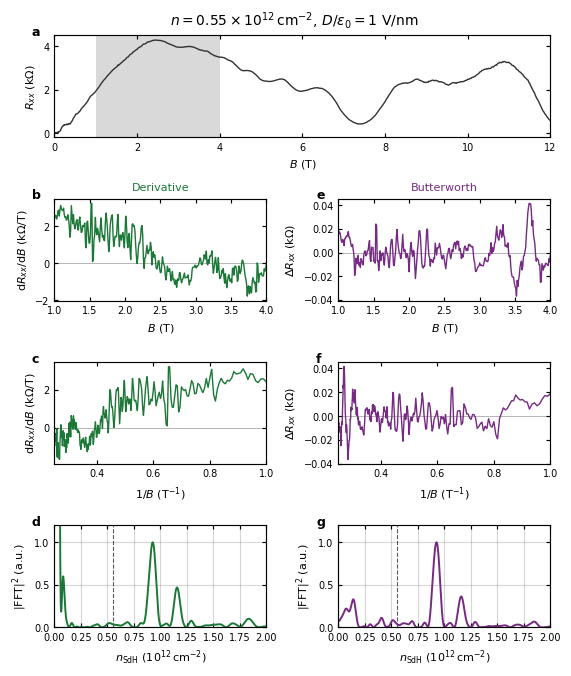

In [13]:
dv_target  = 0.55
dv_methods = ["derivative", "butter"]
dv_labels  = ["Derivative", "Butterworth"]
dv_colors  = ['#1B7837', '#762A83']   # deep green / deep violet
dv_raw_color = '0.2'
dv_zoom    = (1, 4)
dv_zoom_ypad = 0.05
dv_ninv    = 2048
ZF_BG = {'cutoff': 8*0.228, 'order': 4}   # must match the butter_cutoff passed to
                                          # plot_fft_linecut, which uses order 4

fig = plt.figure(figsize=(6.4, 7.4))
gs = GridSpec(4, 2, figure=fig, hspace=0.6, wspace=0.34, top=0.91)
ax_raw = fig.add_subplot(gs[0, :])
axes_det = [fig.add_subplot(gs[1, j]) for j in range(2)]
axes_inv = [fig.add_subplot(gs[2, j]) for j in range(2)]
axes_fft = [fig.add_subplot(gs[3, j]) for j in range(2)]

B_cut, Rxx = zf_cut(dv_target)
fig.suptitle(rf'$n = {dv_target:.2f} \times 10^{{12}}\,\mathrm{{cm}}^{{-2}}$, '
             rf'$D/\epsilon_0 = 1$ V/nm', y=0.945, fontsize=10)

# raw trace, full field range, no processing of any kind
ax_raw.plot(B_cut, Rxx*1e-3, lw=1, color=dv_raw_color)
ax_raw.axvspan(*dv_zoom, color='0.85', zorder=0, lw=0)
ax_raw.set_xlim(0, B_cut.max())
ax_raw.set_ylabel(r'$R_{xx}$ (k$\Omega$)')
ax_raw.set_xlabel(r'$B$ (T)')

m = (dv_zoom[0] <= B_cut) & (B_cut <= dv_zoom[1])

for j, (method, label, color) in enumerate(zip(dv_methods, dv_labels, dv_colors)):
    ax_det, ax_inv, ax_fft = axes_det[j], axes_inv[j], axes_fft[j]
    ax_det.set_title(label, color=color, pad=6)

    if method == "derivative":
        trace_x = B_cut[m]
        trace_y = np.gradient(Rxx[m], B_cut[m])
        ylabel = r'$\mathrm{d}R_{xx}/\mathrm{d}B$ (k$\Omega$/T)'
    else:
        trace_x = np.linspace(*dv_zoom, m.sum())
        trace_y, bg = detrend_butterworth(trace_x,
                                          np.interp(trace_x, B_cut, Rxx), **ZF_BG)
        ylabel = r'$\Delta R_{xx}$ (k$\Omega$)'

    ax_det.plot(trace_x, trace_y*1e-3, lw=1, color=color)
    ax_det.axhline(0, color='0.6', lw=0.5, zorder=0)
    ax_det.set_xlim(*dv_zoom)
    ax_det.set_xlabel(r'$B$ (T)')
    ax_det.set_ylabel(ylabel)

    invB = np.linspace(1/dv_zoom[1], 1/dv_zoom[0], dv_ninv)
    y_inv = np.interp(invB, (1/trace_x)[::-1], trace_y[::-1])
    ax_inv.plot(invB, y_inv*1e-3, lw=1, color=color)
    ax_inv.axhline(0, color='0.6', lw=0.5, zorder=0)
    ax_inv.set_xlim(invB[0], invB[-1])
    ax_inv.set_xlabel(r'$1/B$ (T$^{-1}$)')
    ax_inv.set_ylabel(ylabel)

    print(method)
    _, _, density_res = plot_fft_linecut(fig, ax_fft, dv_target,
                                         filter_method=method,
                                         analyzer=analyzer_lowB,
                                         filter_lims=dv_zoom,
                                         butter_cutoff=8*0.228,
                                         linecut_color=color, verbose=True)
    ax_fft.axvline(density_res, color='0.35', ls='--', lw=0.8, zorder=0)
    ax_fft.grid(True, alpha=0.2, color="0.2")

letters = list(map(chr, range(97, 97 + 26)))
label_spacer = 0.035
for k, ax in enumerate([ax_raw, axes_det[0], axes_inv[0], axes_fft[0],
                        axes_det[1], axes_inv[1], axes_fft[1]]):
    ax.locator_params(axis='y', nbins=4, steps=[1, 2, 5, 10])
    p = ax.get_position()
    fig.text(p.x0 - label_spacer, p.y1, letters[k], fontweight='bold')

plt.savefig('figS_derivative_butter_comp.pdf', dpi=600, bbox_inches='tight',
            pad_inches=0.02, transparent=False)